# Criteo click-through-rate data: exploratory analysis

**Question:** given an ad impression (13 numeric + 26 hashed categorical features), how likely is a click?
Before any model, this notebook looks at the data and writes down the decisions it forces on us.

Dataset: official 100k-row sample of the [Criteo Display Advertising dataset](https://ailab.criteo.com/ressources/)
(`make data` downloads it). Rows are in chronological order; the label is `1` if the ad was clicked.

Plan:
1. Target and class balance
2. Missing values, and whether *missingness itself* predicts clicks
3. Numeric features: heavy tails
4. Does a numeric feature carry signal? CTR by bin
5. Categorical features: cardinality and rare values
6. Drift over time
7. Takeaways → feature-engineering and validation choices

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from criteo_ctr.config import INT_COLS, CAT_COLS, LABEL
from criteo_ctr.io import load_raw

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE = "#2a4a7f"

df = load_raw()
df.shape

(100000, 40)

## 1. Target and class balance

In [2]:
ctr = df[LABEL].mean()
print(f"rows: {len(df):,}   clicks: {df[LABEL].sum():,}   CTR: {ctr:.3f}")
df[LABEL].value_counts(normalize=True).rename("share").to_frame()

rows: 100,000   clicks: 22,663   CTR: 0.227


,share
label,
0,0.77337
1,0.22663


About 1 click in 4. The classes are imbalanced but not extremely, so plain log-loss / AUC are fine and
no re-sampling is needed. The **constant predictor** (always predict 0.226) is the baseline every model has to beat;
its log-loss is computed below (on the test period it is 0.546, see `reports/metrics.md`).

In [3]:
from sklearn.metrics import log_loss
baseline_logloss = log_loss(df[LABEL], np.full(len(df), ctr))
print(f"log-loss of the constant predictor: {baseline_logloss:.4f}")

log-loss of the constant predictor: 0.5352


## 2. Missing values

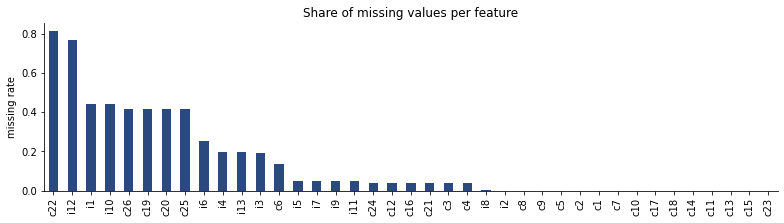

,missing_rate
c22,0.816
i12,0.772
i1,0.444
i10,0.444
c26,0.415
c19,0.415
c20,0.415
c25,0.415


In [4]:
miss = df.isna().mean().drop(LABEL).sort_values(ascending=False)
ax = miss.plot.bar(figsize=(11, 3.2), color=BLUE)
ax.set_title("Share of missing values per feature"); ax.set_ylabel("missing rate")
plt.tight_layout(); plt.show()
miss.head(8).round(3).to_frame("missing_rate")

Missingness is far from random: `i12` is empty in ~77% of rows, `i1` in ~44%, while most categorical columns are
almost complete. Is a missing value informative about the click? Compare CTR for rows with and without a value:

In [5]:
rows = []
for c in INT_COLS:
    m = df[c].isna()
    if 0.01 < m.mean() < 0.99:
        rows.append({"feature": c, "missing_rate": m.mean(),
                     "ctr_if_missing": df.loc[m, LABEL].mean(),
                     "ctr_if_present": df.loc[~m, LABEL].mean()})
miss_ctr = pd.DataFrame(rows).set_index("feature")
miss_ctr["diff"] = miss_ctr["ctr_if_present"] - miss_ctr["ctr_if_missing"]
miss_ctr.round(3).sort_values("diff")

,missing_rate,ctr_if_missing,ctr_if_present,diff
feature,,,,
i3,0.191,0.271,0.216,-0.054
i4,0.195,0.251,0.221,-0.030
i13,0.195,0.251,0.221,-0.030
i12,0.772,0.215,0.265,0.049
i9,0.047,0.125,0.232,0.107
i11,0.047,0.125,0.232,0.107
i7,0.047,0.125,0.232,0.107
i10,0.444,0.160,0.280,0.120
i1,0.444,0.160,0.280,0.120


For `i1` and `i10`, rows **without** a value click at 0.16 versus 0.28 when the value is present; for `i6` the gap is
0.11 vs 0.27, and for `i3` it goes the other way. So "missing" is a category of its own, and it must not be silently
replaced by a mean or zero.

**Decision:** add an explicit `<feature>_missing` indicator for every numeric column, then impute 0 (the linear model
reads the indicator; the tree model can split on it).

## 3. Numeric features are heavy-tailed counts

In [6]:
desc = df[INT_COLS].describe().T[["mean", "50%", "max"]].rename(columns={"50%": "median"})
desc["mean / median"] = (desc["mean"] / desc["median"].replace(0, np.nan)).round(1)
desc.round(1)

,mean,median,max,mean / median
i1,3.8,1.0,556.0,3.8
i2,112.9,3.0,18522.0,37.6
i3,40.7,8.0,65535.0,5.1
i4,8.3,5.0,417.0,1.7
i5,17592.6,2213.0,1741128.0,7.9
i6,139.7,37.0,16290.0,3.8
i7,15.2,3.0,8807.0,5.1
i8,13.6,8.0,4677.0,1.7
i9,125.3,40.0,12661.0,3.1
i10,0.6,1.0,6.0,0.6


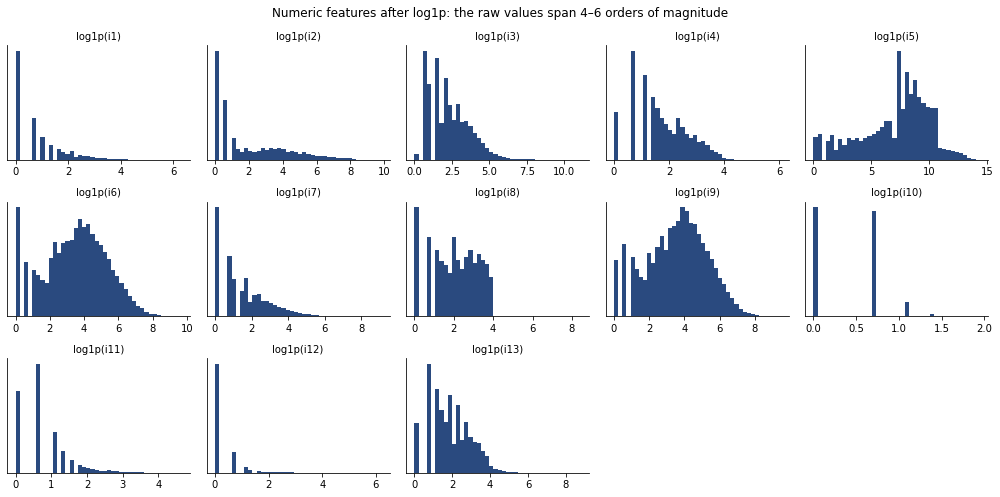

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(14, 7))
for ax, c in zip(axes.flat, INT_COLS):
    x = df[c].dropna().clip(lower=0)
    ax.hist(np.log1p(x), bins=40, color=BLUE)
    ax.set_title(f"log1p({c})", fontsize=10); ax.set_yticks([])
for ax in axes.flat[len(INT_COLS):]:
    ax.axis("off")
fig.suptitle("Numeric features after log1p: the raw values span 4–6 orders of magnitude")
plt.tight_layout(); plt.show()

Means are 2–40× larger than medians (`i5`: mean ≈ 17 600 vs median ≈ 2 200; `i2`: 113 vs 3) and the maxima are in the millions:
these look like event counts. A linear model fed raw counts would be dominated by a handful of outliers.

**Decision:** `log1p` every numeric feature for the logistic regression. Trees are rank-based and do not care.

## 4. Does a numeric feature carry signal? CTR by bin

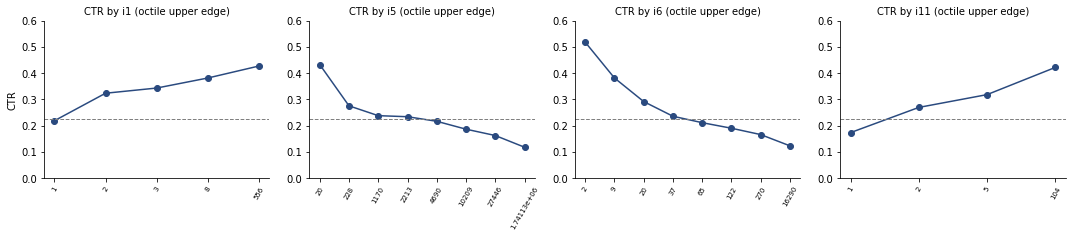

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, c in zip(axes, ["i1", "i5", "i6", "i11"]):
    bins = pd.qcut(df[c], 8, duplicates="drop")
    g = df.groupby(bins, observed=True)[LABEL].agg(["mean", "size"])
    ax.plot(range(len(g)), g["mean"], marker="o", color=BLUE)
    ax.axhline(ctr, ls="--", color="grey", lw=1)
    ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{iv.right:g}" for iv in g.index], rotation=60, fontsize=7)
    ax.set_title(f"CTR by {c} (octile upper edge)", fontsize=10); ax.set_ylim(0, 0.6)
axes[0].set_ylabel("CTR")
plt.tight_layout(); plt.show()

Dashed line = overall CTR. All four features carry strong signal and the relationship is monotone: CTR climbs from
0.22 to 0.43 across the octiles of `i1` and from 0.17 to 0.42 for `i11`, and falls from 0.43 to 0.12 for `i5` and from
0.5 to 0.12 for `i6`. The shape is roughly linear in the *octile*, i.e. in the log of the value, not in the raw value:
another argument for `log1p` in the linear model (a tree model finds the breakpoints itself).

## 5. Categorical features: cardinality and rare values

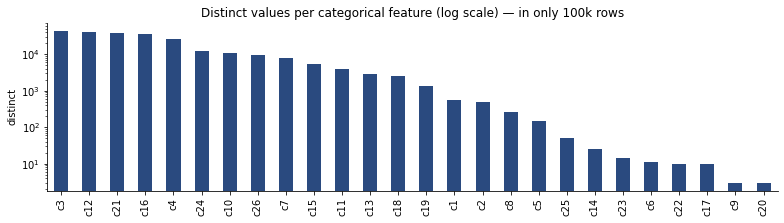

,distinct_values
c3,43869
c12,41311
c21,38617
c16,34616
c4,25183
c24,12334


In [9]:
card = df[CAT_COLS].nunique().sort_values(ascending=False)
ax = card.plot.bar(figsize=(11, 3.2), logy=True, color=BLUE)
ax.set_title("Distinct values per categorical feature (log scale) — in only 100k rows"); ax.set_ylabel("distinct")
plt.tight_layout(); plt.show()
card.head(6).to_frame("distinct_values")

In [10]:
def rare_share(s, threshold=10):
    vc = s.value_counts()
    rare = vc[vc < threshold].index
    return s.isin(rare).mean()

rare = pd.Series({c: rare_share(df[c]) for c in CAT_COLS}).sort_values(ascending=False)
print("share of rows whose value appears < 10 times:")
rare.head(8).round(3).to_frame("rare_share")

share of rows whose value appears < 10 times:


,rare_share
c3,0.544
c12,0.520
c21,0.495
c16,0.460
c4,0.374
c24,0.215
c10,0.215
c7,0.175


Cardinality runs from 3 to ~44 000 distinct hashes (`c3`, `c12`): one-hot encoding would create
~200 000 columns for 100k rows, most seen once. For the five highest-cardinality features, 37–54% of rows carry a value
that appears fewer than 10 times, so the model cannot learn anything reliable about it.

**Decisions:**
- Logistic regression: **hashing trick** (`HashingVectorizer`, 2^18 buckets) — fixed memory, handles unseen values.
- LightGBM: keep values with ≥ 10 train occurrences, map the rest to a single `RARE` token, use native categorical splits.
- Both maps are fitted on the **train** part only (test values unseen in train become `RARE` / hash to some bucket).

## 6. Drift over time

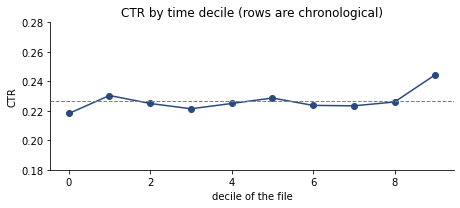

,0,1,2,3,4,5,6,7,8,9
ctr,0.218,0.23,0.225,0.221,0.225,0.229,0.224,0.223,0.226,0.244


In [11]:
decile = pd.qcut(np.arange(len(df)), 10, labels=False)
drift = df.groupby(decile)[LABEL].mean()
ax = drift.plot(marker="o", figsize=(6.5, 3), color=BLUE)
ax.axhline(ctr, ls="--", color="grey", lw=1); ax.set_ylim(0.18, 0.28)
ax.set_title("CTR by time decile (rows are chronological)"); ax.set_xlabel("decile of the file"); ax.set_ylabel("CTR")
plt.tight_layout(); plt.show()
drift.round(3).to_frame("ctr").T

CTR is not stationary: the last decile is ~2 points above the average. In production the model is trained on the
past and scored on the future, so a random train/test split would be optimistic.

**Decision:** split by time — first 80% of rows train, last 20% test (`features.time_split`). Report log-loss, AUC
and a calibration curve on that test set.

## 7. Takeaways

| Finding | What it implies for the pipeline |
|---|---|
| CTR ≈ 0.23, constant-predictor log-loss 0.535 (0.546 on the test period) | baseline to beat; no re-sampling needed |
| missing values are informative (`i1`: 0.16 vs 0.28 CTR) | explicit `*_missing` indicators, then impute 0 |
| numeric features are heavy-tailed counts | `log1p` for the linear model |
| CTR is monotone in the numeric features, roughly linear in their log | log transform for LR, trees find breakpoints |
| cardinality up to 44k, up to half of rows are rare values | hashing trick (LR), rare-value grouping + categorical splits (LightGBM), fitted on train only |
| CTR drifts upward over the file | time-based split, not random |

These decisions are implemented in `src/criteo_ctr/features.py` and evaluated in `src/criteo_ctr/train.py`;
the resulting metrics are in [`reports/metrics.md`](../reports/metrics.md).